# Exploratory analysis: Sinhala News Corpus

What is in the dataset so far, and is it ready for training a topic classifier?

All numbers below are computed from `data/raw/*.csv` when the notebook runs; the statistics come
from the tested module [`analysis/eda.py`](../analysis/eda.py). Notes in *italics* describe the data
**as of 12 October 2026 (583 headlines, 2 days of collection)** and will be revised as the corpus grows.

**Re-run** after more data has been collected:

```bash
pip install -r requirements-analysis.txt
jupyter nbconvert --to notebook --execute --inplace notebooks/01_eda.ipynb
```

> Charts use English labels only: matplotlib cannot shape Sinhala conjuncts (ශ්‍රී, ප්‍ර), so all
> Sinhala text is shown in tables, which render correctly.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from analysis import eda  # noqa: E402

# One quiet house style: single blue series, recessive hairline axes, text in ink greys.
BLUE, INK, INK_2, GRID, SURFACE = "#2a78d6", "#1a1a19", "#5f5e5a", "#e6e5e1", "#fcfcfb"
BLUES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "xtick.color": INK_2, "ytick.color": INK_2, "axes.grid": False,
    "font.size": 10, "figure.dpi": 110,
})
pd.set_option("display.max_colwidth", 90)

df = eda.load_corpus(ROOT / "data" / "raw")
print(f"{len(df):,} headlines from {df['source'].nunique()} publishers, "
      f"collected on {df['collected_day'].nunique()} day(s) "
      f"({df['collected_day'].min()} to {df['collected_day'].max()}).")
print(f"Headline dates range from {df['date'].min().date()} to {df['date'].max().date()} "
      f"(section feeds include older stories on a source's first run).")

583 headlines from 6 publishers, collected on 2 day(s) (2026-10-11 to 2026-10-12).
Headline dates range from 2021-03-01 to 2026-10-12 (section feeds include older stories on a source's first run).


## 1. How fast is it growing?

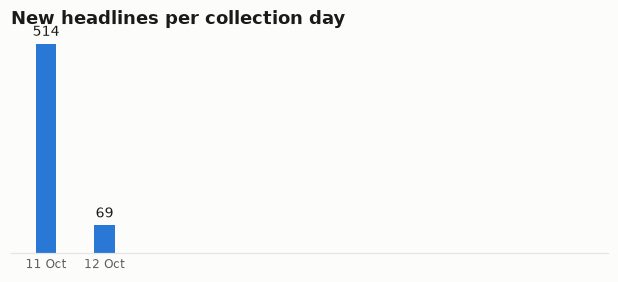

source,ada,lankacnews,lankadeepa,lankatruth,nethnews,siyatha,total
collected_day,,,,,,,
2026-10-11,49,100,51,92,32,190,514
2026-10-12,10,20,13,4,17,5,69


In [2]:
volume = eda.daily_volume(df)
fig, ax = plt.subplots(figsize=(7, 2.6))
days = [d.strftime("%d %b") for d in volume.index]
bars = ax.bar(days, volume["total"], width=0.35, color=BLUE)
ax.set_xlim(-0.6, max(len(days), 10) - 0.4)  # keep bars thin until there are many days
ax.bar_label(bars, labels=[f"{v:,}" for v in volume["total"]], padding=3, color=INK, fontsize=9)
ax.set_title("New headlines per collection day")
ax.tick_params(axis="x", length=0, labelsize=8)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
plt.show()
display(volume)

*As of 12 October: the first day is inflated by back-filling, since each section feed returned its
last 10–50 items at once. From 12 October collection runs every 6 hours; expect roughly 60–120
new headlines a day once the backlog is gone.*

## 2. Label balance

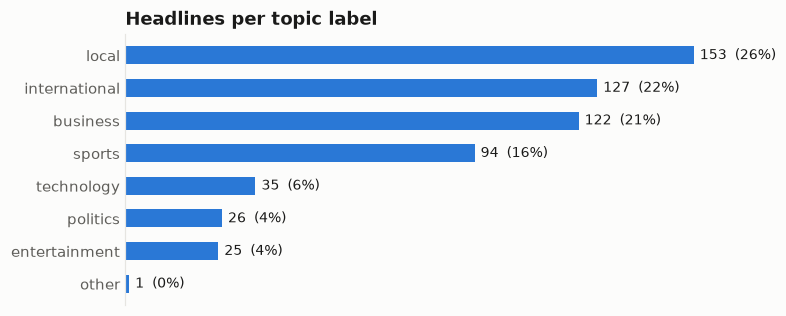

,headlines,share
category,,
politics,26,0.045
business,122,0.209
sports,94,0.161
international,127,0.218
entertainment,25,0.043
technology,35,0.060
local,153,0.262
other,1,0.002


In [3]:
balance = eda.label_balance(df)
order = balance.sort_values("headlines")
fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(order.index, order["headlines"], height=0.55, color=BLUE)
ax.bar_label(bars, labels=[f"{n:,}  ({s:.0%})" for n, s in zip(order["headlines"], order["share"])],
             padding=4, color=INK, fontsize=9)
ax.set_title("Headlines per topic label")
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.show()
display(balance)

*As of 12 October: `local`, `international` and `business` each hold about a fifth of the data;
`politics` (≈4%), `entertainment` (≈4%) and `technology` (≈6%) are small, and `other` is nearly empty.
A first classifier should either drop `other` or merge it, and use class weights or macro-F1 so
the small labels are not ignored.*

## 3. Which publisher supplies which label?

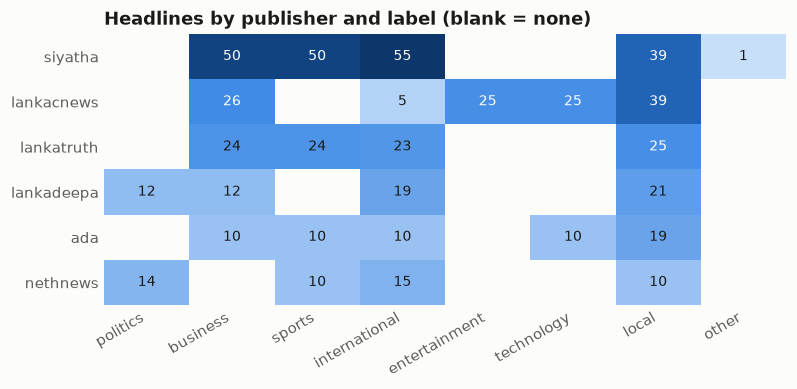

category,politics,business,sports,international,entertainment,technology,local,other,total
source,,,,,,,,,
siyatha,0,50,50,55,0,0,39,1,195
lankacnews,0,26,0,5,25,25,39,0,120
lankatruth,0,24,24,23,0,0,25,0,96
lankadeepa,12,12,0,19,0,0,21,0,64
ada,0,10,10,10,0,10,19,0,59
nethnews,14,0,10,15,0,0,10,0,49


'politics' comes only from: lankadeepa, nethnews
'entertainment' comes only from: lankacnews
'technology' comes only from: ada, lankacnews
'other' comes only from: siyatha


In [4]:
table = eda.source_label_table(df)
labels = [c for c in table.columns if c != "total"]
counts = table[labels]
fig, ax = plt.subplots(figsize=(8, 3.2))
vmax = counts.to_numpy().max()
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("blues", BLUES)
ax.imshow(counts.where(counts > 0), cmap=cmap, vmin=0, vmax=vmax, aspect="auto")
for i in range(counts.shape[0]):
    for j in range(counts.shape[1]):
        n = counts.iat[i, j]
        if n:
            ax.text(j, i, n, ha="center", va="center", fontsize=9, color="white" if n > vmax * 0.45 else INK)
ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right")
ax.set_yticks(range(len(counts.index)), counts.index)
ax.tick_params(length=0)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
ax.set_title("Headlines by publisher and label (blank = none)")
plt.show()
display(table)

only_from = {label: sorted(counts.index[counts[label] > 0]) for label in labels if counts[label].sum()}
for label, sources in only_from.items():
    if len(sources) <= 2:
        print(f"'{label}' comes only from: {', '.join(sources)}")

*As of 12 October this is the most important finding.* Some labels come from very few publishers:
`entertainment` only from Lanka C News, `politics` only from Lankadeepa and Neth News, `technology`
only from Ada and Lanka C News. Each publisher has its own headline style (Lanka C News ends many
headlines with `..`), so a classifier can score well by **recognising the publisher instead of the
topic**. Before training:

- evaluate on a split where it cannot cheat this way (e.g. hold out one publisher at a time, or at least
  report per-publisher scores), and
- add sources that cover these labels, especially politics.

## 4. Headline length

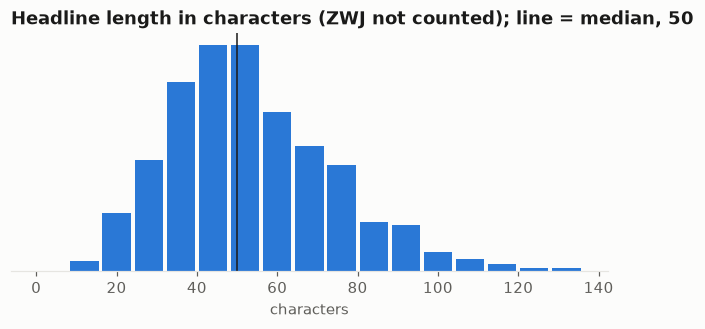

,headlines,chars_median,chars_p90,words_median,words_p90
business,122.0,52.0,74.9,8.0,11.0
entertainment,25.0,55.0,85.2,8.0,12.6
international,127.0,50.0,84.0,7.0,12.0
local,153.0,49.0,77.0,8.0,12.0
other,1.0,37.0,37.0,5.0,5.0
politics,26.0,59.0,91.0,8.0,13.5
sports,94.0,44.5,70.0,7.0,10.0
technology,35.0,58.0,91.2,9.0,13.0
all,583.0,50.0,79.8,8.0,12.0


In [5]:
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(df["chars"], bins=range(0, int(df["chars"].max()) + 10, 8), color=BLUE, rwidth=0.88)
median = df["chars"].median()
ax.axvline(median, color=INK, linewidth=1)
ax.set_title(f"Headline length in characters (ZWJ not counted); line = median, {median:.0f}")
ax.set_xlabel("characters")
ax.spines["left"].set_visible(False)
ax.set_yticks([])
plt.show()
display(eda.length_summary(df).round(1))

*As of 12 October: headlines are short (median ≈ 50 characters, ≈ 8 words), so a model sees very
little text per example. Character n-gram features suit this: they cope with Sinhala suffixes
(තොටුපළට / තොටුපළකට) and with spelling variants.*

## 5. Vocabulary

In [6]:
display(eda.top_terms(df, 20).set_index("word").T)

word,ශ්‍රී,ලංකා,ජනපති,චීන,ලංකාවේ,ගුවන්,ලංකාවට,අවසන්,ලංකාව,බිලියන,අත්අඩංගුවට,පළමු,imf,ඉහළට,ක්‍රිකට්,රුමේෂ්,ඇමති,ණය,ට්‍රම්ප්,ඩොලර්
headlines,53,27,25,21,19,16,14,14,14,14,13,13,13,12,12,12,12,11,11,11


Words most typical of each label (smoothed log-ratio against all other labels):

In [7]:
distinctive = {}
for label in balance.index:
    if balance.loc[label, "headlines"] >= 20:
        distinctive[label] = list(eda.distinctive_terms(df, label, n=8)["word"])
width = max(len(v) for v in distinctive.values())
display(pd.DataFrame({k: v + [""] * (width - len(v)) for k, v in distinctive.items()}))

,politics,business,sports,international,entertainment,technology,local
0,පෙත්සමක්,imf,ක්‍රිකට්,චීනයේ,අවසන්,බුද්ධිය,හිමි
1,ජාතික,ආනයන,එක්දින,චීන,ශ්‍රී,ඩිජිටල්,වෙඩි
2,,ඉක්මවයි,ටෙස්ට්,විරෝධතා,,සමාගමකට,අල්ලයි
3,,ගෑස්,ජයක්,භූ,,ඩ්‍රෝන,අස්වැසුම
4,,බැංකු,හෙල්ල,ඇමරිකා,,ලංකාව,තිදෙනෙක්
5,,සහන,බංග්ලාදේශ,වෙනිසියුලාවේ,,ලංකාවේ,සාකච්ඡාවක්
6,,ආර්ථිකය,තරඟය,ඉරානයට,,ශ්‍රී,කොටු
7,,කින්,විස්ස,තොටුපළට,,,පෞද්ගලික


*As of 12 October: `sports`, `business` and `international` have clearly topical vocabularies
(ක්‍රිකට්, ටෙස්ට්; IMF, ආනයන, බැංකු; චීන, ඇමරිකා, ඉරානයට), which is a good sign that the publishers'
section labels mean what they say. `local` and `politics` share most of their vocabulary.*

## 6. The same story from different publishers

In [8]:
stories = eda.cross_publisher_stories(df)
agreement = eda.label_agreement(stories)
print(f"{len(stories)} stories were reported by two or more publishers "
      f"({stories['headlines'].sum()} headlines, {stories['headlines'].sum() / len(df):.0%} of the corpus).")
print(f"Label agreement: in {agreement:.0%} of them every publisher used the same label.")
disagree = stories[~stories["same_label"]][["date", "publishers", "labels", "example"]]
display(disagree.sort_values(["publishers", "date"], ascending=False).reset_index(drop=True))

20 stories were reported by two or more publishers (49 headlines, 8% of the corpus).
Label agreement: in 70% of them every publisher used the same label.


,date,publishers,labels,example
0,2026-10-12,3,"[local, politics]",චාමර සම්පත් අල්ලස් කොමිසමට
1,2026-10-12,3,"[local, politics]",මහින්ද රෝහල් ගත කරයි
2,2026-10-12,3,"[international, local]",රියාද් ගුවන්තොටුපළට යළි ප්‍රහාරයක්
3,2026-10-11,2,"[international, local]",හෝමූස් පසු කරන්න ගිය බොරතෙල් නැවක් පිපිරී මහා ගින්නක්
4,2026-10-09,2,"[local, politics]",ග්‍රීක බැඳුම්කර සිද්ධිය – අභියාචනා පෙත්සම අජිත් නිවාඩ් කබ්රාල් ඉල්ලා අස්කර ගනී
5,2026-10-09,2,"[local, politics]",ශිරන්ති කොළඹ ජාතික අක්‍ෂි රෝහලට


This is a direct measure of **label noise**: when publishers file the same event under different
labels, one of the labels is arguably "wrong" for a classifier. *As of 12 October about 70% of shared
stories agree; the disagreements are mostly `local` versus `politics` or `international`
(e.g. Mahinda Rajapaksa taken to hospital: `local` for one paper, `politics` for another).*

The grouping is a heuristic (TF-IDF over character trigrams, see `collector/stories.py`): it misses
some pairs and occasionally joins two different stories that share a phrase, so treat these counts as
estimates.

## Takeaways (12 October 2026)

1. **Too early to train**: 583 headlines, mostly from one back-filled day. Re-run this notebook after
   about two weeks of six-hourly collection.
2. **Label imbalance**: `politics`, `entertainment` and `technology` are small; `other` is unusable.
3. **Publisher–label confounding** is the main risk: several labels come from one or two publishers.
   Evaluate with per-publisher breakdowns, and look for more sources with politics and entertainment sections.
4. **Label noise** is moderate (≈70% agreement on shared stories), concentrated in `local` vs
   `politics`/`international`; merging `local` and `politics` is worth testing in the baseline.
5. **Short texts**: character n-grams are the natural first feature set for the baseline classifier.